<a href="https://colab.research.google.com/github/Vandana-kannan/Fshion-Minist-pratice/blob/main/CNN_fashionmnist.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras

In [ ]:
fashion_mnist=keras.datasets.fashion_mnist

In [ ]:
(x_train_full,y_train_full),(x_test,y_test)=fashion_mnist.load_data()

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
class_names=["T-shirt/top","Trouser","Pullover","Dress","Coat","Sandal","Shirt","Sneaker","Bag","Ankle boot"]

In [ ]:
x_train_full=x_train_full.reshape((60000,28,28,1))
x_test=x_test.reshape((10000,28,28,1))

In [ ]:
x_train_n = x_train_full/255
x_test_n = x_test/255

In [ ]:
x_valid,x_train=x_train_n[:5000],x_train_n[5000:]
y_valid,y_train=y_train_full[:5000],y_train_full[5000:]

In [ ]:
x_test=x_test_n

In [ ]:
np.random.seed(42)
tf.random.set_seed(42)

In [ ]:

model=keras.models.Sequential()
model.add(keras.layers.Conv2D(filters=32,kernel_size=(3,3),strides=1,padding="valid",activation="relu",input_shape=(28,28,1)))
model.add(keras.layers.MaxPooling2D((2,2)))
model.add(keras.layers.Flatten())
model.add(keras.layers.Dense(300,activation="relu"))
model.add(keras.layers.Dense(100,activation="relu"))
model.add(keras.layers.Dense(10,activation="softmax"))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 5408)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 300)            │     1,622,700 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 100)            │        30,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,654,130 (6.31 MB)

 Trainable params: 1,654,130 (6.31 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(loss="sparse_categorical_crossentropy",optimizer="sgd",metrics=["accuracy"])

In [ ]:
model_history=model.fit(x_train,y_train,epochs=2,batch_size=64,validation_data=(x_valid,y_valid))

Epoch 1/2
860/860 ━━━━━━━━━━━━━━━━━━━━ 46s 52ms/step - accuracy: 0.7126 - loss: 0.8537 - val_accuracy: 0.7492 - val_loss: 0.6976
Epoch 2/2
860/860 ━━━━━━━━━━━━━━━━━━━━ 44s 51ms/step - accuracy: 0.8075 - loss: 0.5294 - val_accuracy: 0.7904 - val_loss: 0.5777


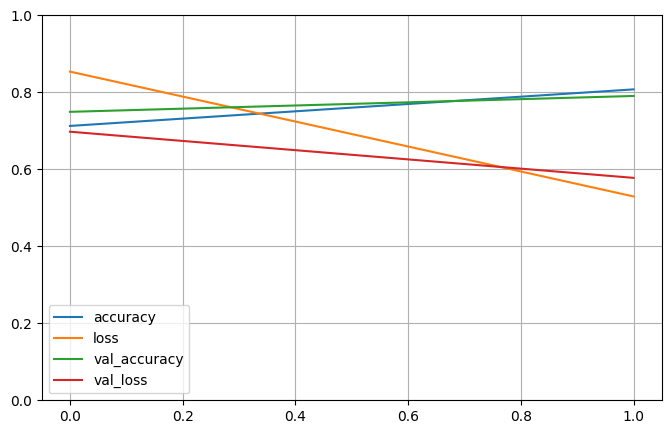

In [ ]:
import pandas as pd
pd.DataFrame(model_history.history).plot(figsize=(8,5))
plt.grid(True)
plt.gca().set_ylim(0,1)
plt.show()

In [ ]:
ev=model.evaluate(x_test_n,y_test)
x_new=x_test[:3]


313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.7618 - loss: 0.6395


In [ ]:
y_pred=model.predict(x_new)
y_pred

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step


array([[2.0129795e-05, 5.7597994e-05, 1.3362058e-04, 2.1272791e-04,
        7.0114635e-05, 3.4298129e-02, 1.8632977e-04, 2.5077537e-01,
        9.3940692e-03, 7.0485193e-01],
       [1.7115512e-05, 3.9392020e-05, 9.1997319e-01, 1.5912507e-05,
        6.3025795e-02, 2.7095561e-09, 1.6891479e-02, 5.9807972e-09,
        3.7077654e-05, 8.0120692e-08],
       [2.2463175e-05, 9.9953568e-01, 2.9131423e-05, 4.3634256e-05,
        3.3992520e-04, 7.4732526e-08, 1.0810829e-05, 9.4296602e-06,
        8.5097481e-06, 2.8309287e-07]], dtype=float32)

In [ ]:
y_test[:3]

array([9, 2, 1], dtype=uint8)

AxesImage(shape=(28, 28))


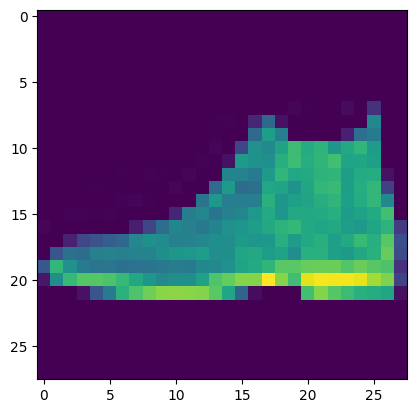

In [ ]:
print(plt.imshow(x_test[0].reshape((28,28))))

In [ ]:
import tensorflow as tf

print(tf.__version__)
print(tf.config.list_physical_devices('GPU'))

2.21.0
[]
